# OMIP runs: SST percentile method & perturbation percentiles

**What's in this notebook**

- Applies the percentile / cold-warm method to OMIP model SST.
- Loads multiple OMIP models; computes percentile trends and confidence intervals.
- Perturbation-SST percentiles.

_Split from `omip_compare.ipynb` (percentiles). Shared helpers in `functions.py`; outputs stripped — re-run to regenerate figures._


In [26]:
# Load Packages 

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import math
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
# from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
# import xesmf as xe
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


In [27]:
import sys, os
# make this repo's functions.py importable from any subfolder
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *  # shared helper functions


In [28]:
# Load variables produced by earlier (compute/loader) notebooks.
# Run those first; harmless if there's nothing saved yet.
load_state(globals())


[load_state] loaded 251 variables from /Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl
[load_state] available: DA_all, In, Out, STATE_DIR, STATE_FILE, all_trend_percentiles, ax, axes, base_path, basin_cmip, basin_era5, basin_jra55 ...


{'In': ['',
  "# Load Packages\nimport numpy as np\nimport xarray as xr\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport matplotlib.transforms as transforms\nimport cartopy.crs as ccrs\nimport calendar, os, re, datetime\nfrom datetime import datetime as _dt\nfrom pathlib import Path\nfrom matplotlib.lines import Line2D\nimport seaborn as sns\nimport pandas as pd\nimport matplotlib.gridspec as gridspec\nfrom scipy.stats import norm, scoreatpercentile\nfrom mpl_toolkits.axes_grid1 import make_axes_locatable\nimport matplotlib.patches as patches\nfrom matplotlib.gridspec import GridSpec\nfrom xhistogram.xarray import histogram\n\nget_ipython().run_line_magic('matplotlib', 'inline')",
  "import sys, os\n_p = os.getcwd()\nfor _ in range(6):\n    if os.path.exists(os.path.join(_p, 'functions.py')):\n        sys.path.insert(0, _p); break\n    _p = os.path.dirname(_p)\nfrom functions import *  # shared helper functions",
  "def quantiles_xhist(data):\n    hist_T = data.sel(lon = sli

# Apply percentile method

- scatter plot with east-west x axis and cold-warm y axis - trend
- trend of each percentile plot like in paper

### Load other OMIP data

In [52]:
models = ['CanESM5', 'EC', 'FGOALS','FIO', 'MRI', 'NorESM2']
#, 'CMCC'
# pull .nc files which contain the model name 

directory_path = '/Users/isabelaconde/Desktop/data/omip/gr/'
# loop through the models and open the files
files = [f for f in os.listdir(directory_path) if f.endswith('.nc')]


models = [f.split('_')[1] for f in files]

model_datasets = {}
for i,file in enumerate(files):

    model_datasets[models[i]] = xr.open_dataset(directory_path+file,decode_times=False)
    print('' + models[i] + ' dataset loaded')
    
# model_datasets# model_datasets

EC-EARTH3 dataset loaded
ACCESS-OM2-JRA55-cycle6 dataset loaded
FGOALS-f3-L dataset loaded
ACCESS-OM2-ERA5 dataset loaded
MRI-ESM2-0 dataset loaded


In [30]:
# mask pacific

def pacific_mask(sst):
    LonsPts_pos = [130,120,110,110,110,260,270,270,277,291,291,130] #-np.ones(13)*180
    LatsPts_pos =[-20,-10,-5,10,20,20,15,15,10,5,-20,-20]
    
    x_pixel_pos = LonsPts_pos
    y_pixel_pos = LatsPts_pos
    
    temp_list = []
    for a, b in zip(x_pixel_pos, y_pixel_pos):
        temp_list.append([a, b])
    
    polygon = np.array(temp_list)
    
    xv, yv = sst.lon.values, sst.lat.values
    lon2d, lat2d = np.meshgrid(xv, yv)
    points = np.hstack((lon2d.reshape((-1,1)), lat2d.reshape((-1,1))))
    path = matplotlib.path.Path(polygon)
    mask = path.contains_points(points)
    mask.shape = lon2d.shape
    mask_bit_pos = mask*np.ones_like(lon2d)
    
    mask_mods = mask_bit_pos#+mask_bit_neg
    
    mask_mods[mask_mods==0] = np.nan
    return mask_mods


# mask models
def mask_models(model_datasets):
    for model, dataset in model_datasets.items():
        print('Masking ' + model)
        dataset['sst'] = dataset['sst'].where(pacific_mask(dataset['sst']) == 1)
        dataset['sst'].attrs['long_name'] = 'Sea Surface Temperature'
        dataset['sst'].attrs['units'] = 'C'
        print(model + ' masked')
    return model_datasets

# mask models
model_datasets = mask_models(model_datasets)

Masking EC-EARTH3
EC-EARTH3 masked
Masking ACCESS-OM2-JRA55-cycle6
ACCESS-OM2-JRA55-cycle6 masked
Masking FGOALS-f3-L
FGOALS-f3-L masked
Masking ACCESS-OM2-ERA5
ACCESS-OM2-ERA5 masked
Masking MRI-ESM2-0
MRI-ESM2-0 masked


# Percentiles 

In [31]:
# load percentile data processed in gadi 

mod_labs = ['MRI-ESM2-0', 'FGOALS-f3-L','EC-EARTH3','ACCESS-OM2-JRA55-cycle6_iaf','ACCESS-OM2-ERA5']

save_directory = '/Users/isabelaconde/Desktop/data/omip/sst_percentiles/'

file_paths = [f"{save_directory}SST_percentile_{model}_1982-2018_gr.nc" for model in mod_labs]

# some datasets have cftime - change in loop below
import datetime
td = datetime.datetime.strptime("1982-01-01", "%Y-%m-%d")
k = 444
d = pd.date_range(td, periods=k, freq='MS')

dict_percentiles_omip = {}

for i, file in enumerate(file_paths):
    dict_percentiles_omip[mod_labs[i]] = xr.open_dataarray(file).assign_coords({'time': d})



In [51]:

# apply function to each model

percentiles_omip_trend = {}
for i, da in enumerate(mod_labs):
    
    percentiles_omip_trend[da]=find_trend_percentile(dict_percentiles_omip[da].sel(time = slice('1982','2017')))
    print('trend calculated for ' + mod_labs[i])

# for i in range(len(mod_labs)):
#     # plot trends of highest and lowest model 
#     percentiles_omip_trend[mod_labs[i]].plot(label = mod_labs[i])  



# plt.legend()

trend calculated for MRI-ESM2-0
trend calculated for FGOALS-f3-L
trend calculated for EC-EARTH3
trend calculated for ACCESS-OM2-JRA55-cycle6_iaf
trend calculated for ACCESS-OM2-ERA5


In [33]:
# load percentile trend 1982--2018
# make DA_all 
# load percentile trend 1982--2018

trend_percentile = xr.open_datatree('/Users/isabelaconde/Desktop/data/dt_cmip_percentiles_trend_1982-2018.nc')

# find mods
# Get ensemble names - yes so you can call on it later
models =['CESM1-CAM5',
 'CanESM2',
 'GFDL-ESM2M',
 'MPI-ESM',
 'ACCESS-ESM1-5',
 'CanESM5',
 'EC-Earth3',
 'IPSL-CM6A-LR',
 'MIROC-ES2L',
 'MIROC6',
 'MPI-ESM1-2-LR',
 'CESM2',
 'GFDL-SPEAR-MED']

data_tree=trend_percentile

mods = {}
for model_name, model_data in data_tree.items():
    en=[]
    for ensemble_name, ensemble_data in data_tree[model_name].items():
        en.extend([str(ensemble_name)])
    
    mods[str(model_name)]=en

    
trend_dt=trend_percentile
model_array=[]
da=[]

for m in range(len(models)):
    sources = mods[models[m]][0:len(mods[models[m]])]
    # da=[] # initialise array for grad values
    for i in range(len(sources)):
        da.extend(trend_dt[models[m]].grad.values)

DA_all = xr.DataArray(np.squeeze(da), dims=['run','area'], coords={'run': np.linspace(0, 1, 519), 'area': np.linspace(0, 1, 100)})


In [34]:
# DA_all= xr.open_dataarray('/Users/isabelaconde/Desktop/data/final_data/da_all_cmip56_runs.nc')

def calculate_confidence_intervals_all(data, n):
    mean = np.empty(n)
    lower = np.empty(n)
    upper = np.empty(n)

    for i in range(data.shape[0]):
        mean[i] = np.mean(data[i])
        lower[i] = scoreatpercentile(data[i],10)
        upper[i] = scoreatpercentile(data[i],90)

    return mean, lower, upper

# Plot for first three models
num=100
data = DA_all.values.T * 10 * 12
mean, lower, upper = calculate_confidence_intervals_all(data, num)
df = pd.DataFrame({'mean': DA_all.mean(dim='run').values * 10 * 12, 
                   'min': DA_all.min(dim='run').values * 10 * 12, 
                   'max': DA_all.max(dim='run').values * 10 * 12, 
                   'lower': lower, 'upper': upper,
                   'area': np.linspace(0, 1, 100)})

noaa_percentile_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/cmip_compare/noaa_percentile_trend.nc')
cobe_percentile_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/cmip_compare/cobe_percentile_trend.nc')
had_percentile_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/cmip_compare/ersst_percentile_trend.nc')

obs_mean = (noaa_percentile_trend+cobe_percentile_trend+had_percentile_trend)/3


In [35]:
from xhistogram.xarray import histogram

def percentiles_xhist(data): # find percentiles of SST using xhistogram
    hist_T = data.squeeze()
    weights = np.cos(np.deg2rad(hist_T.lat))
    times = hist_T['time']
    const_area=np.r_[0:1:0.01]
    temps = np.r_[12:34:0.5] # define temperatures for binning 
    
    temps_interp = np.empty([len(times),len(const_area)])
    
    for i in np.r_[0:len(times):1]:  
        h=histogram(hist_T[i],bins=temps,weights=weights).cumsum()
        hh = (h - h[0])/(h[-1]-h[0])
        temps_interp[i]=np.interp(const_area,hh,temps[1:])
    
    
    sst_area= xr.DataArray(temps_interp,coords={'time':times,'area':const_area})

    return(sst_area)

def pacific_mask(sst):

    LonsPts_pos = [130,120,110,110,110,260,270,270,277,291,291,130] #-np.ones(13)*180
    LatsPts_pos =[-20,-10,-5,10,20,20,15,15,10,5,-20,-20]
    
    x_pixel_pos = LonsPts_pos
    y_pixel_pos = LatsPts_pos
    
    temp_list = []
    for a, b in zip(x_pixel_pos, y_pixel_pos):
        temp_list.append([a, b])
    
    polygon = np.array(temp_list)
    
    xv, yv = sst.lon.values, sst.lat.values
    lon2d, lat2d = np.meshgrid(xv, yv)
    points = np.hstack((lon2d.reshape((-1,1)), lat2d.reshape((-1,1))))
    path = matplotlib.path.Path(polygon)
    mask = path.contains_points(points)
    mask.shape = lon2d.shape
    mask_bit_pos = mask*np.ones_like(lon2d)

    mask_mods = mask_bit_pos
    
    mask_mods[mask_mods==0] = np.nan
    return mask_mods


def trend_obs_percentile(data): # find trend of percentile data
    time_axis = np.arange(data.sizes['time'])
    trends = np.empty(data.sizes['area'])
    for i in range(data.sizes['area']):
        y = data[:, i].values
        trends[i] = np.polyfit(time_axis, y, 1)[0]  # slope

    return xr.DataArray(trends, coords={'area': data.area}, dims='area', name='sst_trend')


noaa_sst = xr.open_dataset('/Users/isabelaconde/Desktop/data/conde2025/NOAA_sst.mon.mean.nc').sst.sel(time = slice('1982','2024')).sel(lat = slice(-80,80))
noaa_sst_pacific = (pacific_mask(noaa_sst)*noaa_sst).sel(lat=slice(-20,20), lon = slice(100,300))
noaa_sst_percentiles = percentiles_xhist(noaa_sst_pacific)
noaa_sst_trend = trend_obs_percentile(noaa_sst_percentiles)


In [36]:
control_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_control.nc')
era5_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_era5.nc')
perturb_percent_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_merra2_percentile_trend.nc')
# perturb_percent_era5_uas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_percentile_era5_uas_trend.nc')
perturb_percent_era5_uas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/1deg_jra55_iaf_era5_uas_trend_percentile.nc')
perturb_percent_era5_uas_vas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_uas_vas.nc')
perturb_percent_era5_huss_tas_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_huss_tas.nc')
perturb_percent_era5_rsds_rlds_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_rsds_rlds.nc')
perturb_percent_era5_winds = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_era5_winds.nc')
perturb_percent_all_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/ACCESS-OM2_runs/perturb_percentile_trend_all_trend.nc')
perturb_percent_winds_mean_trend = xr.open_dataarray('/Users/isabelaconde/Desktop/data/omip/processed/perturb_percentile_trend_uas_vas_mean_trend.nc')


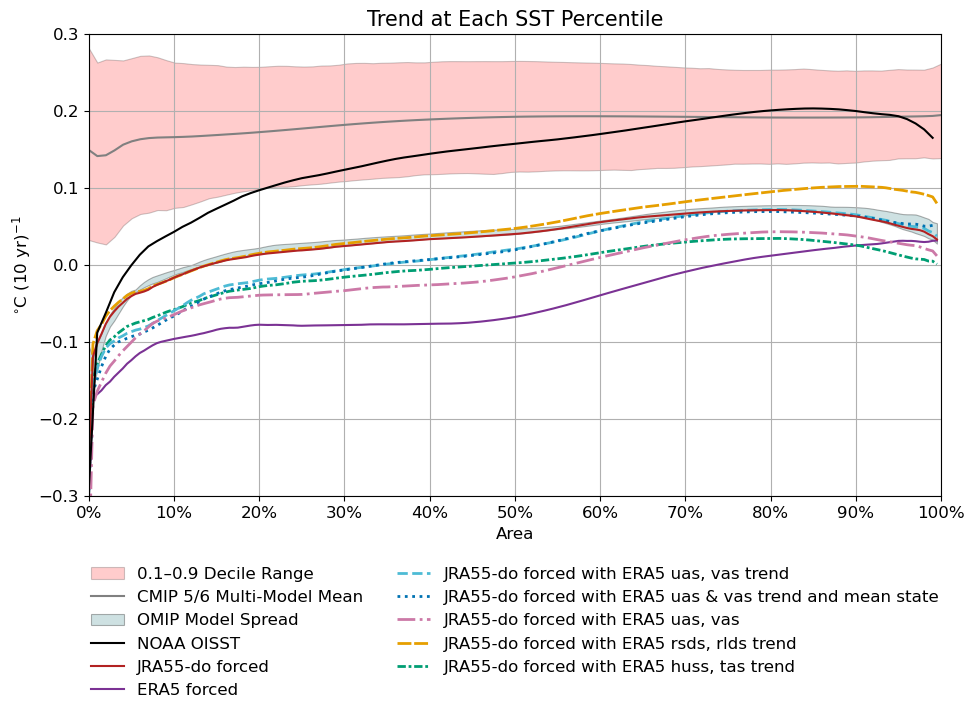

In [61]:
colors = [
    '#B22222',  # firebrick
    '#7B3294',  # darker purple
    '#4DBBD5',  # softer cyan
    '#0072B2',  # Okabe-Ito blue
    '#CC79A7',  # magenta instead of violet
    '#E69F00',  # orange
    '#009E73',  # bluish green instead of limegreen
    '#000000',  # black
]

fig, axes = plt.subplots(figsize=(11, 6))

# -------------------------
# OMIP SHADED REGION (exclude last model)
# -------------------------
omip_models = mod_labs[:-1]          # all except last
special_mod = mod_labs[-1]           # last model (plot separately)

# Stack all OMIP models
omip_stack = xr.concat(
    [percentiles_omip_trend[m] for m in omip_models],
    dim='model'
) * 12 * 10

# Ensemble stats
omip_min  = omip_stack.min(dim='model')
omip_max  = omip_stack.max(dim='model')
omip_mean = omip_stack.mean(dim='model')

# Shaded region
axes.fill_between(
    omip_stack.area,
    omip_min,
    omip_max,
    color='cadetblue',
    alpha=0.3,
    edgecolor='k',
    linewidth=0.8,
    label='OMIP Model Spread'
)

(era5_percent_trend * 12 * 10).plot(
    ax=axes,
    color=colors[1],
    label='ERA5 forced',
    lw=1.5
)

# -------------------------
# ACCESS-OM2 runs
# -------------------------
(perturb_percent_era5_rsds_rlds_trend*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 rsds, rlds trend', color=colors[5], ls=(0, (5, 1)), lw=2)
((perturb_percent_era5_huss_tas_trend)*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 huss, tas trend', color=colors[6], ls=(0, (3, 1, 1, 1)), lw=2)

(perturb_percent_era5_uas_vas_trend*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 uas, vas trend', color=colors[2], ls='--', lw=2)
((perturb_percent_winds_mean_trend)*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 uas & vas trend and mean state', color=colors[3], ls=':', lw=2)
((perturb_percent_era5_winds)*12*10).plot(ax=axes, label='JRA55-do forced with ERA5 uas, vas', color=colors[4], ls='-.', lw=2)
(control_percent_trend*12*10).plot(ax=axes, label='JRA55-do forced', color=colors[0])

# -------------------------
# CMIP + envelope  (mm mean NOT multiplied)
# -------------------------
sns.lineplot(x="area", y="mean", data=df, ax=axes, color='grey', label='CMIP 5/6 Multi-Model Mean')
axes.fill_between(df['area'], df['upper'], df['lower'], alpha=0.2, color='red',
                  edgecolor='k', linewidth=0.8,
                  label='0.1–0.9 Decile Range')

# NOAA observational line
axes.plot(noaa_sst_trend.area.values, noaa_sst_trend.values * 10 * 12,
          color=colors[7], label='NOAA OISST')

# -------------------------
# Formatting
# -------------------------
axes.set_xticks(np.linspace(0, 1, 11))
axes.set_xticklabels([f'{int(x*100)}%' for x in np.linspace(0, 1, 11)])
axes.grid(True)
axes.set_xlim(0, 1)
axes.set_ylim(-0.3, 0.3)
axes.set_ylabel(r'$^{\circ}$C (10 yr)$^{-1}$', fontsize=12)
axes.set_xlabel('Area', fontsize=12)
axes.tick_params(axis='both', labelsize=12)
plt.title('Trend at Each SST Percentile', fontsize=15)

# -------------------------
# Legend below plot, 2 columns, custom order
# -------------------------
handles, labels = axes.get_legend_handles_labels()
label_to_handle = dict(zip(labels, handles))
legend_order = [
    '0.1–0.9 Decile Range',
    'CMIP 5/6 Multi-Model Mean',
    'OMIP Model Spread',
    'NOAA OISST',
    'JRA55-do forced',
    'ERA5 forced',
    'JRA55-do forced with ERA5 uas, vas trend',
    'JRA55-do forced with ERA5 uas & vas trend and mean state',
    'JRA55-do forced with ERA5 uas, vas',
    'JRA55-do forced with ERA5 rsds, rlds trend',
    'JRA55-do forced with ERA5 huss, tas trend',
]
axes.legend(
    [label_to_handle[l] for l in legend_order],
    legend_order,
    loc='upper center', bbox_to_anchor=(0.5, -0.12),
    ncol=2, fontsize=12, frameon=False,
)

outpath = "/Users/isabelaconde/Desktop/trend_percentile.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

In [ ]:
save_state(globals())

